<a href="https://colab.research.google.com/github/Abraham-on-del/AF4-Robot-manipulador-2-GDL/blob/main/AF4_Proyecto_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Simulacion completada: 10 segundos
Angulos finales q1, q2 [grados]: [25.28 29.69]
Angulos deseados finales [grados]: [28.23 31.26]
M(0), C(0), G(0), F(0) iniciales:
M =
 [[1.837 0.415]
 [0.415 0.144]]
C =
 [[ 0.  0.]
 [-0.  0.]]
G =
 [19.708  3.478]
F =
 [0. 0.]


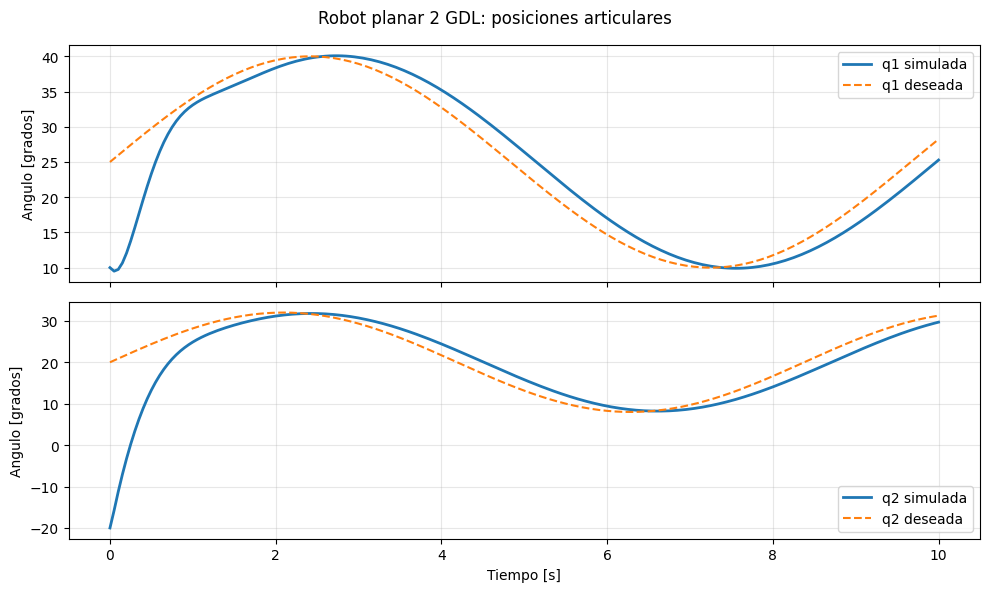

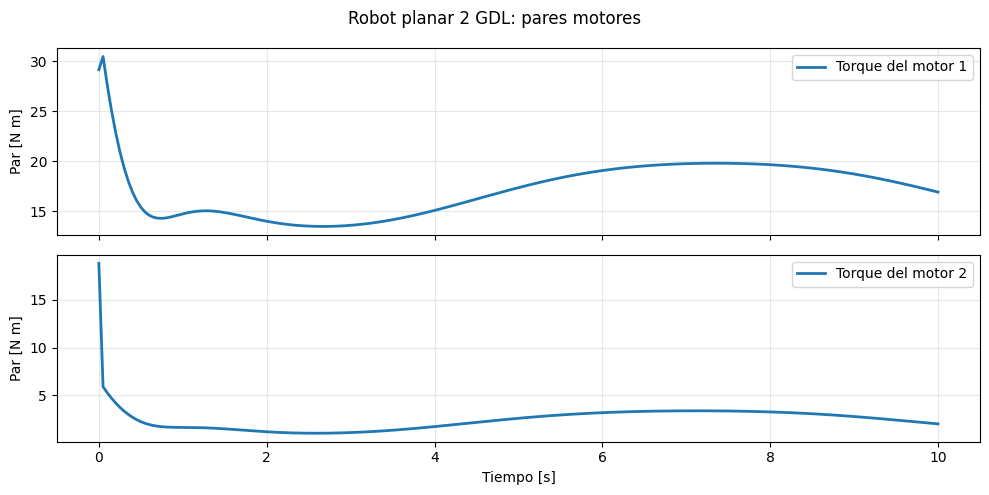

Animacion GIF de 10 segundos guardada: robot_2gdl_10s.gif


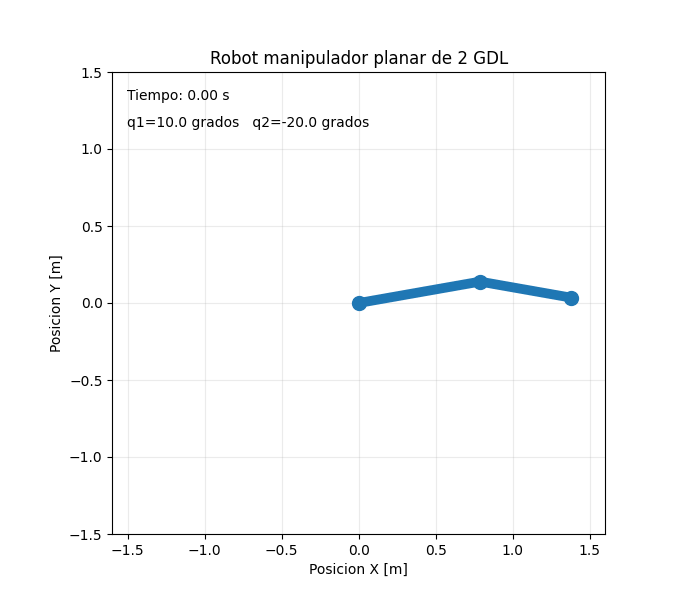

In [1]:
# AF4 - Robot manipulador planar de 2 GDL


import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import display, Image

# 1. Parametros fisicos (SI)
l1, l2 = 0.8, 0.6                 # Longitud de eslabones [m]
m1, m2 = 1.8, 1.2                 # Masas [kg]
r1, r2 = l1/2, l2/2              # Centros de masa [m]
I1, I2 = m1*l1**2/12, m2*l2**2/12  # Inercias respecto al CM [kg*m^2]
g = 9.81                          # Gravedad [m/s^2]
b1, b2 = 0.12, 0.08               # Friccion viscosa [N*m*s/rad]
Kp = np.array([36.0, 22.0])       # Control proporcional
Kd = np.array([11.0, 7.0])        # Control derivativo

# 2. Matrices M(q), C(q,dq), G(q) y F(dq)
def matrices(q, dq):
    q1, q2 = q
    v1, v2 = dq
    A = I1 + I2 + m1*r1**2 + m2*(l1**2 + r2**2)
    B = m2*l1*r2
    D = I2 + m2*r2**2

    M = np.array([[A + 2*B*np.cos(q2), D + B*np.cos(q2)],
                  [D + B*np.cos(q2),   D]])
    C = np.array([[-B*np.sin(q2)*v2, -B*np.sin(q2)*(v1+v2)],
                  [ B*np.sin(q2)*v1,  0.0]])
    G = np.array([g*((m1*r1+m2*l1)*np.cos(q1) + m2*r2*np.cos(q1+q2)),
                  g*m2*r2*np.cos(q1+q2)])
    F = np.array([b1*v1, b2*v2])
    return M, C, G, F

# 3. Trayectoria deseada de las articulaciones [rad]
def referencia(t):
    return np.deg2rad([25 + 15*np.sin(0.65*t),
                       20 + 12*np.sin(0.75*t)])

# 4. Pares de motor: controlador PD + compensacion de gravedad
def torque(t, q, dq):
    G = matrices(q, dq)[2]
    return G + Kp*(referencia(t)-q) - Kd*dq

# 5. Ecuacion dinamica M*ddq + C*dq + G + F = tau
def sistema(t, x):
    q, dq = x[:2], x[2:]
    M, C, G, F = matrices(q, dq)
    ddq = np.linalg.solve(M, torque(t, q, dq) - C@dq - G - F)
    return np.r_[dq, ddq]

# 6. Simulacion durante 10 segundos
T = np.linspace(0, 10, 201)
x0 = np.deg2rad([10, -20, 0, 0])  # [q1,q2,dq1,dq2]
sol = solve_ivp(sistema, [0, 10], x0, t_eval=T, rtol=1e-8, atol=1e-10)
if not sol.success:
    raise RuntimeError(sol.message)
q, dq = sol.y[:2], sol.y[2:]
qd = np.array([referencia(t) for t in sol.t]).T
Tau = np.array([torque(t, q[:, i], dq[:, i])
                for i, t in enumerate(sol.t)]).T

print('Simulacion completada: 10 segundos')
print('Angulos finales q1, q2 [grados]:', np.round(np.rad2deg(q[:, -1]), 2))
print('Angulos deseados finales [grados]:', np.round(np.rad2deg(qd[:, -1]), 2))
print('M(0), C(0), G(0), F(0) iniciales:')
for nombre, valor in zip(('M', 'C', 'G', 'F'), matrices(q[:, 0], dq[:, 0])):
    print(nombre, '=\n', np.round(valor, 3))

# 7. Graficas de posicion angular
fig, ejes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for i, ax in enumerate(ejes):
    ax.plot(sol.t, np.rad2deg(q[i]), label=f'q{i+1} simulada', linewidth=2)
    ax.plot(sol.t, np.rad2deg(qd[i]), '--', label=f'q{i+1} deseada')
    ax.set_ylabel('Angulo [grados]')
    ax.grid(True, alpha=0.3)
    ax.legend()
ejes[1].set_xlabel('Tiempo [s]')
fig.suptitle('Robot planar 2 GDL: posiciones articulares')
plt.tight_layout()
fig.savefig('curvas_robot_2gdl.png', dpi=150)
plt.show()

# 8. Graficas de pares motores
fig, ejes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for i, ax in enumerate(ejes):
    ax.plot(sol.t, Tau[i], label=f'Torque del motor {i+1}', linewidth=2)
    ax.set_ylabel('Par [N m]')
    ax.grid(True, alpha=0.3)
    ax.legend()
ejes[1].set_xlabel('Tiempo [s]')
fig.suptitle('Robot planar 2 GDL: pares motores')
plt.tight_layout()
fig.savefig('pares_motor_2gdl.png', dpi=150)
plt.show()

# 9. Animacion completa
fig, ax = plt.subplots(figsize=(7, 6))
ax.set_aspect('equal')
ax.set_xlim(-1.6, 1.6)
ax.set_ylim(-1.5, 1.5)
ax.set_xlabel('Posicion X [m]')
ax.set_ylabel('Posicion Y [m]')
ax.set_title('Robot manipulador planar de 2 GDL')
ax.grid(True, alpha=0.25)
linea, = ax.plot([], [], 'o-', linewidth=7, markersize=10)
tiempo_txt = ax.text(0.03, 0.94, '', transform=ax.transAxes)
angulos_txt = ax.text(0.03, 0.88, '', transform=ax.transAxes)

def actualizar(i):
    q1, q2 = q[:, i]
    x1, y1 = l1*np.cos(q1), l1*np.sin(q1)
    x2 = x1 + l2*np.cos(q1+q2)
    y2 = y1 + l2*np.sin(q1+q2)
    linea.set_data([0, x1, x2], [0, y1, y2])
    tiempo_txt.set_text(f'Tiempo: {sol.t[i]:.2f} s')
    angulos_txt.set_text(f'q1={np.rad2deg(q1):.1f} grados   q2={np.rad2deg(q2):.1f} grados')
    return linea, tiempo_txt, angulos_txt

animacion = FuncAnimation(fig, actualizar, frames=range(200),
                          interval=50, blit=True)
animacion.save('robot_2gdl_10s.gif', writer=PillowWriter(fps=20))
plt.close(fig)
print('Animacion GIF de 10 segundos guardada: robot_2gdl_10s.gif')
display(Image(filename='robot_2gdl_10s.gif'))


